In [1]:
# ==============================================================================
# CELL 0: CONFIGURATION, IMPORTS & MONKEY PATCH
# ==============================================================================
%load_ext autoreload
%autoreload 2

import os
import h5py
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from matplotlib.colors import LogNorm

import fake_spectra.spectra as spectra
import fake_spectra.abstractsnapshot as absn
import fake_spectra.unitsystem as unitsystem
import fake_spectra.gas_properties as gas_properties

def matplotlib_default_config():
    font = {'family' : 'serif', 'weight' : 'normal', 'size'   : 14}
    rcnew = {
        "mathtext.fontset" : "cm", "text.usetex": False, 'figure.frameon': True,
        'axes.linewidth': 2., "axes.titlesize" : 24, "axes.labelsize" : 24,
        "legend.fontsize" : 16, 'legend.fancybox': True, 'lines.linewidth': 2.5,
        'xtick.alignment': 'center', 'xtick.bottom': True, 'xtick.color': 'black',
        'xtick.direction': 'in', 'xtick.labelbottom': True, 'xtick.labelsize': 20,
        'xtick.major.bottom': True, 'xtick.major.pad': 6.0, 'xtick.major.size': 10.0,
        'xtick.major.width': 1.5, 'xtick.minor.bottom': True, 'xtick.minor.pad': 3.4,
        'xtick.minor.size': 5.0, 'xtick.minor.visible': True, 'xtick.minor.width': 1.0,
        'xtick.top': True, 'ytick.alignment': 'center_baseline', 'ytick.color': 'black',
        'ytick.direction': 'in', 'ytick.labelleft': True, 'ytick.labelsize': 20,
        'ytick.left': True, 'ytick.major.left': True, 'ytick.major.pad': 6.0,
        'ytick.major.size': 10.0, 'ytick.major.width': 1.5, 'ytick.minor.left': True,
        'ytick.minor.pad': 3.4, 'ytick.minor.right': True, 'ytick.minor.size': 5.0,
        'ytick.minor.visible': True, 'ytick.minor.width': 1.0, 'ytick.right': True
    }
    return font, rcnew

%matplotlib widget 
font, rcnew = matplotlib_default_config()
plt.rc('font', **font)
plt.rcParams.update(rcnew)

# --- Safe Loader for MN5 ---
def safe_get_header_attr(self, attr):
    if attr == "NumPart_Total_HighWord":
        return np.zeros(6, dtype=np.int32)
    try:
        val = self._f_handle["Header"].attrs[attr]
        if isinstance(val, np.ndarray) and np.size(val) == 1:
            try:
                return val[0]
            except IndexError:
                return val
        return val
    except KeyError:
        if "Parameters" in self._f_handle:
            try:
                return self._f_handle["Parameters"].attrs[attr]
            except KeyError:
                pass
        raise KeyError(f"Could not find attribute '{attr}'")

absn.AbstractSnapshot.get_header_attr = safe_get_header_attr


# ==============================================================================
# CELL 1: CUSTOM PHYSICS CLASSES (MN5)
# ==============================================================================
class MN5GasProperties(gas_properties.GasProperties):
    def __init__(self, **kwargs):
        super().__init__(**kwargs)
        if self.absnap is not None:
            try:
                self.PhysDensThresh = self.absnap.get_header_attr("SelfShieldingDensity")
                print(f" -> MN5GasProperties: Ground Truth SF threshold loaded: {self.PhysDensThresh} atoms/cm^3")
            except KeyError:
                self.PhysDensThresh = 0.1295
        else:
            self.PhysDensThresh = 0.1295


Target Halo ID: 300
Position: [283.13162 200.1886  220.75534] code units
Velocity: [ 52.955433 -48.061176 -63.368107] km/s
Mass: 5.93e+01 code units
R200: 0.20 code units

Loading particles from snapshot into memory for 2D map...


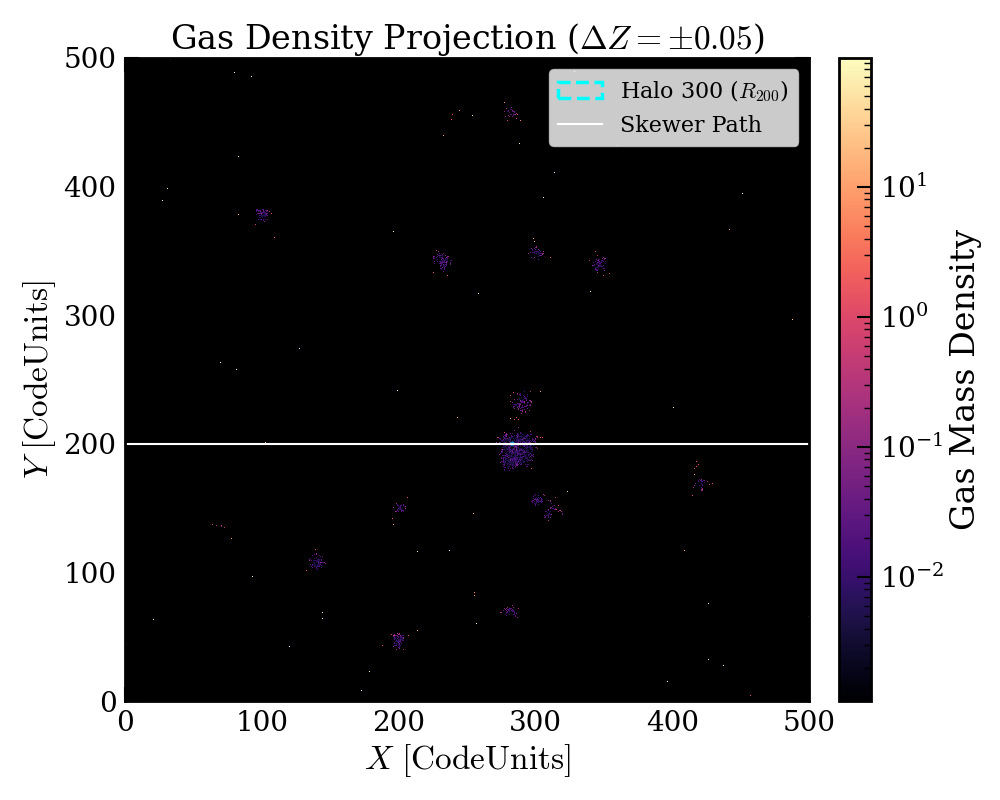


Running fake_spectra native extraction (Mode: None)...
Reloading from snapshot (will save to:  ./dummy_none.hdf5  )
 -> MN5GasProperties: Ground Truth SF threshold loaded: 0.1295 atoms/cm^3
1  sightlines. resolution:  10.000813673834802  z= 2.978397693934533
rank = 0 | Interpolation 12.5 percent done
rank = 0 | Interpolation 25.0 percent done
rank = 0 | Interpolation 37.5 percent done
rank = 0 | Interpolation 50.0 percent done
rank = 0 | Interpolation 62.5 percent done
rank = 0 | Interpolation 75.0 percent done
rank = 0 | Interpolation 87.5 percent done
rank = 0 | Interpolation 12.5 percent done
rank = 0 | Interpolation 25.0 percent done
rank = 0 | Interpolation 37.5 percent done
rank = 0 | Interpolation 50.0 percent done
rank = 0 | Interpolation 62.5 percent done
rank = 0 | Interpolation 75.0 percent done
rank = 0 | Interpolation 87.5 percent done
rank = 0 | Interpolation 12.5 percent done
rank = 0 | Interpolation 25.0 percent done
rank = 0 | Interpolation 37.5 percent done
rank = 0 

TypeError: Spectra.__init__() got an unexpected keyword argument 'dla_phys_thresh'

In [2]:
# ==============================================================================
# CELL 2: SIMULATION PARAMETERS & SMART HALO SEARCH
# ==============================================================================
base_path = '/home/STORAGE/MN5_resims/fiducial/hydro_output'
snap_num = "094"
target_halo_id = 300 
slice_half_width = 0.050 # Map slice remains ultra-thin exactly as requested

def get_halo_info(base_dir, snap_number, halo_id):
    group_dir = os.path.join(base_dir, f"groups_{snap_number}")
    file0 = os.path.join(group_dir, f"fof_subhalo_tab_{snap_number}.0.hdf5")
    with h5py.File(file0, 'r') as f:
        num_files = f['Header'].attrs.get('NumFiles', f['Header'].attrs.get('NumFilesPerSnapshot', 1))
        box_size = f['Header'].attrs['BoxSize']
        
    current_id_offset = 0
    for i in range(num_files):
        filepath = os.path.join(group_dir, f"fof_subhalo_tab_{snap_number}.{i}.hdf5")
        if not os.path.exists(filepath): continue
        with h5py.File(filepath, 'r') as f:
            if 'Group' not in f or 'Group_M_Crit200' not in f['Group']: continue
            n_halos = len(f['Group']['Group_M_Crit200'])
            if halo_id < current_id_offset + n_halos:
                local_index = halo_id - current_id_offset
                pos = f['Group']['GroupPos'][local_index]
                vel = f['Group']['GroupVel'][local_index]
                mass = f['Group']['Group_M_Crit200'][local_index]
                r200 = f['Group']['Group_R_Crit200'][local_index]
                return pos, vel, mass, r200, box_size
            current_id_offset += n_halos
    raise ValueError(f"Halo ID {halo_id} not found.")

halo_pos, halo_vel, halo_mass, halo_r200, box_size = get_halo_info(base_path, snap_num, target_halo_id)

shift_Mpch = 0
x_sk = halo_pos[0]#+shift_Mpch
y_sk = halo_pos[1]#+shift_Mpch
z_sk = halo_pos[2] 
cofm = np.array([[x_sk, y_sk, z_sk]])
axis = np.array([1], dtype=np.int32) 

print(f"Target Halo ID: {target_halo_id}")
print(f"Position: {halo_pos} code units")
print(f"Velocity: {halo_vel} km/s")
print(f"Mass: {halo_mass:.2e} code units")
print(f"R200: {halo_r200:.2f} code units")


# ==============================================================================
# CELL 3: LOAD GAS PARTICLES FOR 2D MAP ONLY
# ==============================================================================
print("\nLoading particles from snapshot into memory for 2D map...")
snap_file_0 = os.path.join(base_path, f'snapdir_{snap_num}', f'snapshot_{snap_num}.0.hdf5')
with h5py.File(snap_file_0, 'r') as f:
    num_snap_files = f['Header'].attrs.get('NumFilesPerSnapshot', f['Header'].attrs.get('NumFiles', 1))
    header = f['Header'].attrs
    hubble = header.get('HubbleParam', 0.6774)
    a_scale = header.get('Time', 1.0)
    z_sim = header.get('Redshift', (1.0/a_scale) - 1.0)

map_x, map_y, map_mass = [], [], []

for i in range(num_snap_files):
    snap_file = os.path.join(base_path, f'snapdir_{snap_num}', f'snapshot_{snap_num}.{i}.hdf5')
    if not os.path.exists(snap_file): continue
    
    with h5py.File(snap_file, 'r') as f:
        if 'PartType0' not in f: continue

        coords = f['PartType0']['Coordinates'][:]
        masses = f['PartType0']['Masses'][:]
        
        # --- Data for 2D Map ---
        dz_map = np.abs(coords[:, 2] - z_sk)
        dz_map = np.where(dz_map > box_size / 2.0, box_size - dz_map, dz_map)
        mask_map = dz_map <= slice_half_width 
        
        if np.sum(mask_map) > 0:
            map_x.append(coords[:, 0][mask_map])
            map_y.append(coords[:, 1][mask_map])
            map_mass.append(masses[mask_map])

gas_x_map = np.concatenate(map_x)
gas_y_map = np.concatenate(map_y)
gas_mass_map = np.concatenate(map_mass)


# ==============================================================================
# CELL 4: 2D GAS DENSITY PROJECTION (CONTEXT MAP)
# ==============================================================================
fig1, ax1 = plt.subplots(figsize=(10, 8))
ax1.set_facecolor('black')

h_map, xedges, yedges, img = ax1.hist2d(
    gas_x_map, gas_y_map, bins=2000, 
    range=[[0, box_size], [0, box_size]], weights=gas_mass_map, 
    cmap='magma', norm=LogNorm()
)
circle = patches.Circle(
    (halo_pos[0], halo_pos[1]), radius=halo_r200, 
    linewidth=2.5, edgecolor='cyan', facecolor='none', linestyle='--', 
    label=rf'Halo {target_halo_id} ($R_{{200}}$)'
)
ax1.add_patch(circle)
ax1.axhline(y=y_sk, color='white', linestyle='-', linewidth=1.5, label='Skewer Path')
ax1.set_xlabel(r'$X \ [\mathrm{Code Units}]$')
ax1.set_ylabel(r'$Y \ [\mathrm{Code Units}]$')
ax1.set_title(rf'Gas Density Projection ($\Delta Z = \pm {slice_half_width}$)')
ax1.set_xlim(0, box_size)
ax1.set_ylim(0, box_size)
ax1.legend(loc='upper right', facecolor='white', framealpha=0.8)
cbar = fig1.colorbar(img, ax=ax1, fraction=0.046, pad=0.04)
cbar.set_label(r'Gas Mass Density')
plt.tight_layout()
plt.show()


# ==============================================================================
# CELL 5: FAKE SPECTRA NATIVE EXTRACTION (MODE: NONE)
# ==============================================================================
print("\nRunning fake_spectra native extraction (Mode: None)...")

mn5_units = unitsystem.UnitSystem(
    UnitLength_in_cm=3.085678e24, 
    UnitMass_in_g=1.989e43, 
    UnitVelocity_in_cm_per_s=1e5
)

ss_none = spectra.Spectra(
    snap_num, base_path, cofm=cofm, axis=axis, 
    res=10, savedir=".", savefile="dummy_none.hdf5", reload_file=True,
    units=mn5_units, gasprop=MN5GasProperties, sf_neutral=True, filter_mode="None"
)

flux_fs = np.exp(-ss_none.get_tau("H", 1, 1215)[0, :])
nHI_fs = ss_none.get_density("H", 1)[0, :]
nH_fs = ss_none.get_density("H", -1)[0, :] 
temp_fs = ss_none.get_temp("H", -1)[0, :] 

nbins = ss_none.nbins
vmax = ss_none.vmax
c_light = 299792.458 
lam_rest = 1215.67   

v_axis = np.arange(nbins) * (vmax / nbins)
chi_axis = np.linspace(0, box_size, nbins)

halo_v_center = (halo_pos[0] / box_size) * vmax


# ==============================================================================
# CELL 6: KINEMATIC & SPATIAL CENTERING
# ==============================================================================
print("\nCentralizing spectrum to Halo Rest Frame & Spatial Center...")

v_cosmo = (halo_pos[0] / box_size) * vmax
v_pec_x = halo_vel[0] * np.sqrt(a_scale)
v_sys = v_cosmo + v_pec_x

v_rel_wrapped = (v_axis - v_sys + vmax / 2.0) % vmax - vmax / 2.0
sort_idx_v = np.argsort(v_rel_wrapped)
v_common = np.linspace(-vmax / 2.0, vmax / 2.0, nbins)

flux_centered = np.interp(v_common, v_rel_wrapped[sort_idx_v], flux_fs[sort_idx_v])

chi_rel_wrapped = (np.arange(nbins) * (box_size / nbins) - halo_pos[0] + box_size / 2.0) % box_size - box_size / 2.0
sort_idx_chi = np.argsort(chi_rel_wrapped)
chi_common_plot = np.linspace(-box_size / 2.0, box_size / 2.0, nbins) 

# Apply physical space centering to densities AND temperature
nHI_centered = np.interp(chi_common_plot, chi_rel_wrapped[sort_idx_chi], nHI_fs[sort_idx_chi])
temp_centered = np.interp(chi_common_plot, chi_rel_wrapped[sort_idx_chi], temp_fs[sort_idx_chi])


# ==============================================================================
# CELL 7: TOPOLOGICAL EXTRACTION (DLAS AND NO-DLAS)
# ==============================================================================
print("\nExtracting DLAs-only spectrum (Hybrid Region Growing active)...")
ss_dlas = spectra.Spectra(
    snap_num, base_path, cofm=cofm, axis=axis, res=10, 
    savedir=".", savefile="dummy_dlas.hdf5", reload_file=True,
    units=mn5_units, gasprop=MN5GasProperties, sf_neutral=True, 
    filter_mode="DLAs", dla_phys_thresh="auto"
)
flux_dlas = np.exp(-ss_dlas.get_tau("H", 1, 1215)[0, :])
nHI_dlas_fs = ss_dlas.get_density("H", 1)[0, :] 

print("\nExtracting No-DLAs (Forest-only) spectrum...")
ss_nodlas = spectra.Spectra(
    snap_num, base_path, cofm=cofm, axis=axis, res=10, 
    savedir=".", savefile="dummy_nodlas.hdf5", reload_file=True,
    units=mn5_units, gasprop=MN5GasProperties, sf_neutral=True, 
    filter_mode="No_DLAs", dla_phys_thresh="auto"
)
flux_nodlas = np.exp(-ss_nodlas.get_tau("H", 1, 1215)[0, :])
nHI_nodlas_fs = ss_nodlas.get_density("H", 1)[0, :] 

# Center fluxes using the established common velocity space
flux_dlas_centered = np.interp(v_common, v_rel_wrapped[sort_idx_v], flux_dlas[sort_idx_v])
flux_nodlas_centered = np.interp(v_common, v_rel_wrapped[sort_idx_v], flux_nodlas[sort_idx_v])

# Center masked densities using the established spatial space
nHI_dlas_centered = np.interp(chi_common_plot, chi_rel_wrapped[sort_idx_chi], nHI_dlas_fs[sort_idx_chi])
nHI_nodlas_centered = np.interp(chi_common_plot, chi_rel_wrapped[sort_idx_chi], nHI_nodlas_fs[sort_idx_chi])

# Retrieve Hybrid Extraction Thresholds
core_thresh_nH = ss_dlas.dla_phys_thresh_nH
core_thresh_nHI = ss_dlas.dla_phys_thresh_nHI
envelope_thresh_nH = getattr(ss_dlas, 'dla_envelope_thresh', core_thresh_nH * 1e-2)

print(f"\nTopological Thresholds:")
print(f" -> Neutral Hydrogen Core Trigger (nHI): {core_thresh_nHI:.2e} cm^-3")
print(f" -> Total Hydrogen CGM Envelope (nH): {envelope_thresh_nH:.2e} cm^-3")


# ==============================================================================
# CELL 8: FLUX DECOMPOSITION & MULTIPLICATIVE RESIDUAL PLOTS
# ==============================================================================
fig_decomp, axes = plt.subplots(3, 1, figsize=(12, 12), sharex=True)

axes[0].plot(v_common, flux_centered, color='black', lw=1.5, label='Mode: None (Full Spectrum)')
axes[0].set_title(f'Spectral Decomposition (Halo {target_halo_id}, z={z_sim:.2f})')

axes[1].plot(v_common, flux_dlas_centered, color='crimson', lw=1.5, label='Mode: DLAs Only (Cores + Inner CGM)')
axes[2].plot(v_common, flux_nodlas_centered, color='forestgreen', lw=1.5, label='Mode: No DLAs (Pure IGM Forest)')
axes[2].set_xlabel(r'Relative Velocity $v - v_{\mathrm{sys}}$ [km/s]')

for ax in axes:
    ax.set_ylabel('Transmitted Flux')
    ax.axvline(0.0, color='blue', linestyle='--', lw=1.5, alpha=0.7, label='Halo Velocity Center')
    ax.set_xlim(-vmax / 2.0, vmax / 2.0)
    ax.set_ylim(-0.05, 1.05)
    ax.grid(True, alpha=0.3, linestyle='--')
    ax.legend(loc='lower right')

plt.tight_layout()
plt.show()

# Multiplicative Residual Validation
flux_multiplication = flux_nodlas_centered * flux_dlas_centered
fig_res, (ax_top, ax_bot) = plt.subplots(2, 1, figsize=(12, 7), sharex=True, gridspec_kw={'height_ratios': [3, 1]})

ax_top.plot(v_common, flux_multiplication, color='black', lw=1.5, alpha=0.6, label='Reconstruction (DLAs $\\times$ No DLAs)')
ax_top.plot(v_common, flux_centered, linestyle=':', color='limegreen', lw=2, label='True Total Flux (None)')
ax_top.axvline(0.0, color='red', linestyle='--', lw=2, alpha=0.8, label='Halo Center')
ax_top.set_ylabel('Transmitted Flux')
ax_top.set_title('Reconstruction Validation: Full Spectrum vs Multiplied Components')
ax_top.set_ylim(-0.05, 1.05)
ax_top.grid(True, alpha=0.3, linestyle='--')
ax_top.legend(loc='lower right')

residuals = flux_multiplication - flux_centered
ax_bot.plot(v_common, residuals, color='blue', lw=1.5)
ax_bot.axhline(0.0, color='black', linestyle='--', lw=1)
ax_bot.axvline(0.0, color='red', linestyle='--', lw=1.5, alpha=0.8)
ax_bot.set_xlabel(r'Relative Velocity $v - v_{\mathrm{sys}}$ [km/s]')
ax_bot.set_ylabel('Residual')
ax_bot.set_xlim(-vmax / 2.0, vmax / 2.0)
ax_bot.grid(True, alpha=0.3, linestyle='--')

plt.tight_layout()
plt.show()


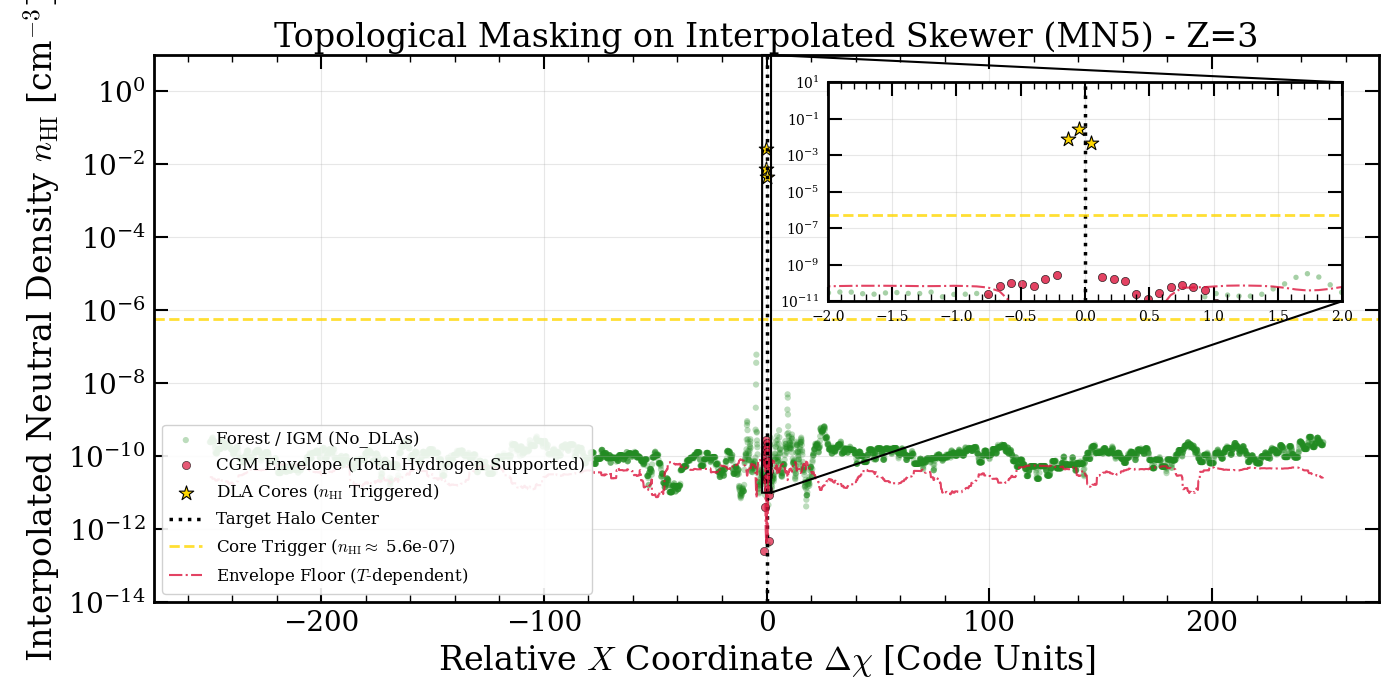

In [ ]:
# ==============================================================================
# CELL 9: DISCRETE ANATOMY PLOT (DENSITY MASK VALIDATION)
# ==============================================================================
mask_dla = nHI_dlas_centered > 1e-15
mask_nodla = nHI_nodlas_centered > 1e-15
mask_core = (nHI_dlas_centered >= core_thresh_nHI) & mask_dla
mask_cgm_envelope = mask_dla & ~mask_core

fig_anat, ax_anat = plt.subplots(figsize=(14, 7))

ax_anat.scatter(chi_common_plot[mask_nodla], nHI_nodlas_centered[mask_nodla], 
                color='forestgreen', alpha=0.3, edgecolors='none', s=20, label='Forest / IGM (No_DLAs)')

ax_anat.scatter(chi_common_plot[mask_cgm_envelope], nHI_dlas_centered[mask_cgm_envelope], 
                color='crimson', alpha=0.7, edgecolors='black', linewidth=0.5, s=35, label='CGM Envelope (Total Hydrogen Supported)')

ax_anat.scatter(chi_common_plot[mask_core], nHI_dlas_centered[mask_core], 
                color='gold', alpha=1.0, edgecolors='black', linewidth=0.8, s=120, marker='*', label='DLA Cores ($n_{\\rm HI}$ Triggered)')

ax_anat.axvline(0.0, color='black', linestyle=':', lw=2.5, label='Target Halo Center')
ax_anat.axhline(core_thresh_nHI, color='gold', linestyle='--', lw=2, alpha=0.8, 
                label=f'Core Trigger ($n_{{\\rm HI}} \\approx$ {core_thresh_nHI:.1e})')

# Exact dynamic envelope curve based on local interpolated Temperature
fHI_env_dynamic = ss_none.gasprop._neutral_fraction(envelope_thresh_nH, temp_centered)
env_thresh_nHI_dynamic = envelope_thresh_nH * fHI_env_dynamic

ax_anat.plot(chi_common_plot, env_thresh_nHI_dynamic, color='crimson', linestyle='-.', lw=1.5, alpha=0.8, 
             label='Envelope Floor ($T$-dependent)')

ax_anat.set_yscale('log')
ax_anat.set_ylim(1e-14, 1e1)
#ax_anat.set_xlim(-box_size / 2000.0, box_size / 2000.0)

ax_anat.set_xlabel(r'Relative $X$ Coordinate $\Delta \chi$ [Code Units]')
ax_anat.set_ylabel(r'Interpolated Neutral Density $n_{\mathrm{HI}}$ [cm$^{-3}$]')
ax_anat.set_title(f'Topological Masking on Interpolated Skewer (MN5) - Z={z_sim:.0f}')
ax_anat.legend(loc='lower left', framealpha=0.9, fontsize=12, ncol=1) 
ax_anat.grid(True, alpha=0.3)

# INSET Zoom
axins = ax_anat.inset_axes([0.55, 0.55, 0.42, 0.40]) 

axins.scatter(chi_common_plot[mask_nodla], nHI_nodlas_centered[mask_nodla], 
              color='forestgreen', alpha=0.4, edgecolors='none', s=15)
axins.scatter(chi_common_plot[mask_cgm_envelope], nHI_dlas_centered[mask_cgm_envelope], 
              color='crimson', alpha=0.8, edgecolors='black', linewidth=0.5, s=35)
axins.scatter(chi_common_plot[mask_core], nHI_dlas_centered[mask_core], 
              color='gold', alpha=1.0, edgecolors='black', linewidth=0.8, s=120, marker='*')

axins.axvline(0.0, color='black', linestyle=':', lw=2.5)
axins.axhline(core_thresh_nHI, color='gold', linestyle='--', lw=2, alpha=0.8)
axins.plot(chi_common_plot, env_thresh_nHI_dynamic, color='crimson', linestyle='-.', lw=1.5, alpha=0.8)

x_zoom = 2 
axins.set_xlim(-x_zoom, x_zoom)
axins.set_ylim(1e-11, 1e1)
axins.set_yscale('log')
axins.grid(True, alpha=0.3)
axins.tick_params(labelsize=10)

ax_anat.indicate_inset_zoom(axins, edgecolor="black", alpha=1.0, lw=1.5)

plt.tight_layout()
plt.show()


Paper-ready figure saved successfully as:
 -> HCD_detection.pdf
 -> HCD_detection.png


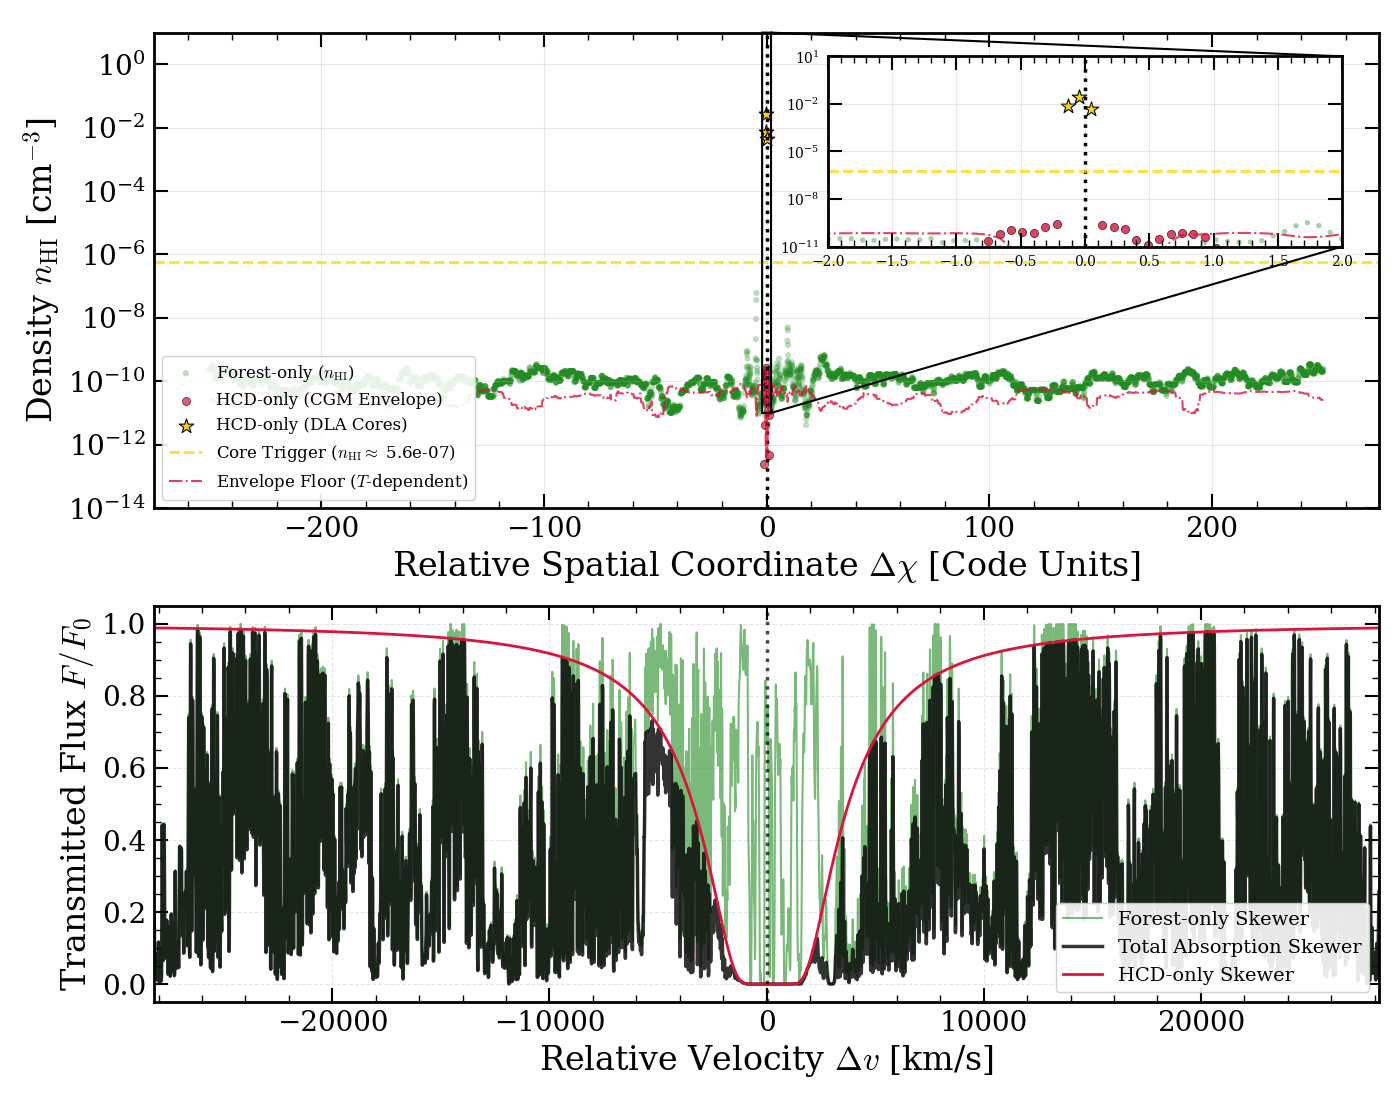

In [ ]:
# ==============================================================================
# CELL 10: PAPER-READY COMBINED FIGURE (HCD DETECTION)
# ==============================================================================
fig, (ax_top, ax_bot) = plt.subplots(2, 1, figsize=(14, 11), gridspec_kw={'height_ratios': [1.2, 1]})

# ------------------------------------------------------------------------------
# TOP PANEL: Topological Masking (Density Anatomy)
# ------------------------------------------------------------------------------
ax_top.scatter(chi_common_plot[mask_nodla], nHI_nodlas_centered[mask_nodla], 
               color='forestgreen', alpha=0.3, edgecolors='none', s=20, label='Forest-only ($n_{\\rm HI}$)')

ax_top.scatter(chi_common_plot[mask_cgm_envelope], nHI_dlas_centered[mask_cgm_envelope], 
               color='crimson', alpha=0.7, edgecolors='black', linewidth=0.5, s=35, label='HCD-only (CGM Envelope)')

ax_top.scatter(chi_common_plot[mask_core], nHI_dlas_centered[mask_core], 
               color='gold', alpha=1.0, edgecolors='black', linewidth=0.8, s=120, marker='*', label='HCD-only (DLA Cores)')

ax_top.axvline(0.0, color='black', linestyle=':', lw=2.5)
ax_top.axhline(core_thresh_nHI, color='gold', linestyle='--', lw=2, alpha=0.8, 
               label=f'Core Trigger ($n_{{\\rm HI}} \\approx$ {core_thresh_nHI:.1e})')

ax_top.plot(chi_common_plot, env_thresh_nHI_dynamic, color='crimson', linestyle='-.', lw=1.5, alpha=0.8, 
             label='Envelope Floor ($T$-dependent)')

ax_top.set_yscale('log')
ax_top.set_ylim(1e-14, 1e1)
# Hide the x label of the top panel to avoid clutter,
# since the spatial (top) and kinematic (bottom) axes are different.
ax_top.set_xlabel(r'Relative Spatial Coordinate $\Delta \chi$ [Code Units]')
ax_top.set_ylabel(r'Density $n_{\mathrm{HI}}$ [cm$^{-3}$]')
ax_top.legend(loc='lower left', framealpha=0.9, fontsize=12, ncol=1) 
ax_top.grid(True, alpha=0.3)

# INSET Zoom for Top Panel
axins = ax_top.inset_axes([0.55, 0.55, 0.42, 0.40]) 
axins.scatter(chi_common_plot[mask_nodla], nHI_nodlas_centered[mask_nodla], color='forestgreen', alpha=0.4, edgecolors='none', s=15)
axins.scatter(chi_common_plot[mask_cgm_envelope], nHI_dlas_centered[mask_cgm_envelope], color='crimson', alpha=0.8, edgecolors='black', linewidth=0.5, s=35)
axins.scatter(chi_common_plot[mask_core], nHI_dlas_centered[mask_core], color='gold', alpha=1.0, edgecolors='black', linewidth=0.8, s=120, marker='*')

axins.axvline(0.0, color='black', linestyle=':', lw=2.5)
axins.axhline(core_thresh_nHI, color='gold', linestyle='--', lw=2, alpha=0.8)
axins.plot(chi_common_plot, env_thresh_nHI_dynamic, color='crimson', linestyle='-.', lw=1.5, alpha=0.8)

x_zoom = 2 
axins.set_xlim(-x_zoom, x_zoom)
axins.set_ylim(1e-11, 1e1)
axins.set_yscale('log')
axins.grid(True, alpha=0.3)
axins.tick_params(labelsize=10)

ax_top.indicate_inset_zoom(axins, edgecolor="black", alpha=1.0, lw=1.5)

# ------------------------------------------------------------------------------
# BOTTOM PANEL: Spectral Decomposition (Overplotted Fluxes)
# ------------------------------------------------------------------------------
# Plotting order is important here so the lines don't completely hide each other.
# 1. Forest (Green, slightly transparent so we can see the black behind it)
ax_bot.plot(v_common, flux_nodlas_centered, color='forestgreen', lw=1.5, alpha=0.6, label='Forest-only Skewer')

# 2. Total Flux (Black, slightly thicker to serve as the baseline envelope)
ax_bot.plot(v_common, flux_centered, color='black', lw=2.5, alpha=0.8, label='Total Absorption Skewer')

# 3. HCD-only (Crimson, drawn last to boldly show the Voigt damping wings)
ax_bot.plot(v_common, flux_dlas_centered, color='crimson', lw=2.0, label='HCD-only Skewer')

# Kinematic Center Marker
ax_bot.axvline(0.0, color='black', linestyle=':', lw=2.5, alpha=0.7)

ax_bot.set_xlim(-vmax / 2.0, vmax / 2.0)
ax_bot.set_ylim(-0.05, 1.05)
ax_bot.set_xlabel(r'Relative Velocity $\Delta v$ [km/s]')
ax_bot.set_ylabel(r'Transmitted Flux $F/F_0$')
ax_bot.grid(True, alpha=0.3, linestyle='--')
ax_bot.legend(loc='lower right', framealpha=0.9, fontsize=14)

# Align panels beautifully and save
plt.tight_layout()

# Saving as PDF (vector graphics, perfect for ApJ) and PNG (for quick LaTeX preview)
pdf_path = "HCD_detection.pdf"
png_path = "HCD_detection.png"

plt.savefig(pdf_path, format='pdf', dpi=300, bbox_inches='tight')
plt.savefig(png_path, format='png', dpi=300, bbox_inches='tight')

print(f"\nPaper-ready figure saved successfully as:\n -> {pdf_path}\n -> {png_path}")
plt.show()